# Data Collection and Processing: Workflow Overview

| Item | Description |
|---|---|
| Goal | Guide a reader through the D section: what text was collected, from where, in which order, and what each notebook leaves behind for the later sections. |
| Covers | The ten notebooks of D1 to D4, their inputs and outputs, where the data live, and how to obtain every input again. |
| Output | None. This notebook runs no step and writes no file. |
| Run | Not applicable. The ten D notebooks ran in August 2026; each one states that in its own header. |

D collects the three bodies of text the project uses and turns them into the tables the later sections read: congressional hearing transcripts, C-SPAN's abstracts of the same hearings, and the Business section of 10-K filings. No language model runs in this section.

## 1. The process at a glance

The chart below is the D flowchart from `R - Results/figures/D - Data Collection and Processing`.

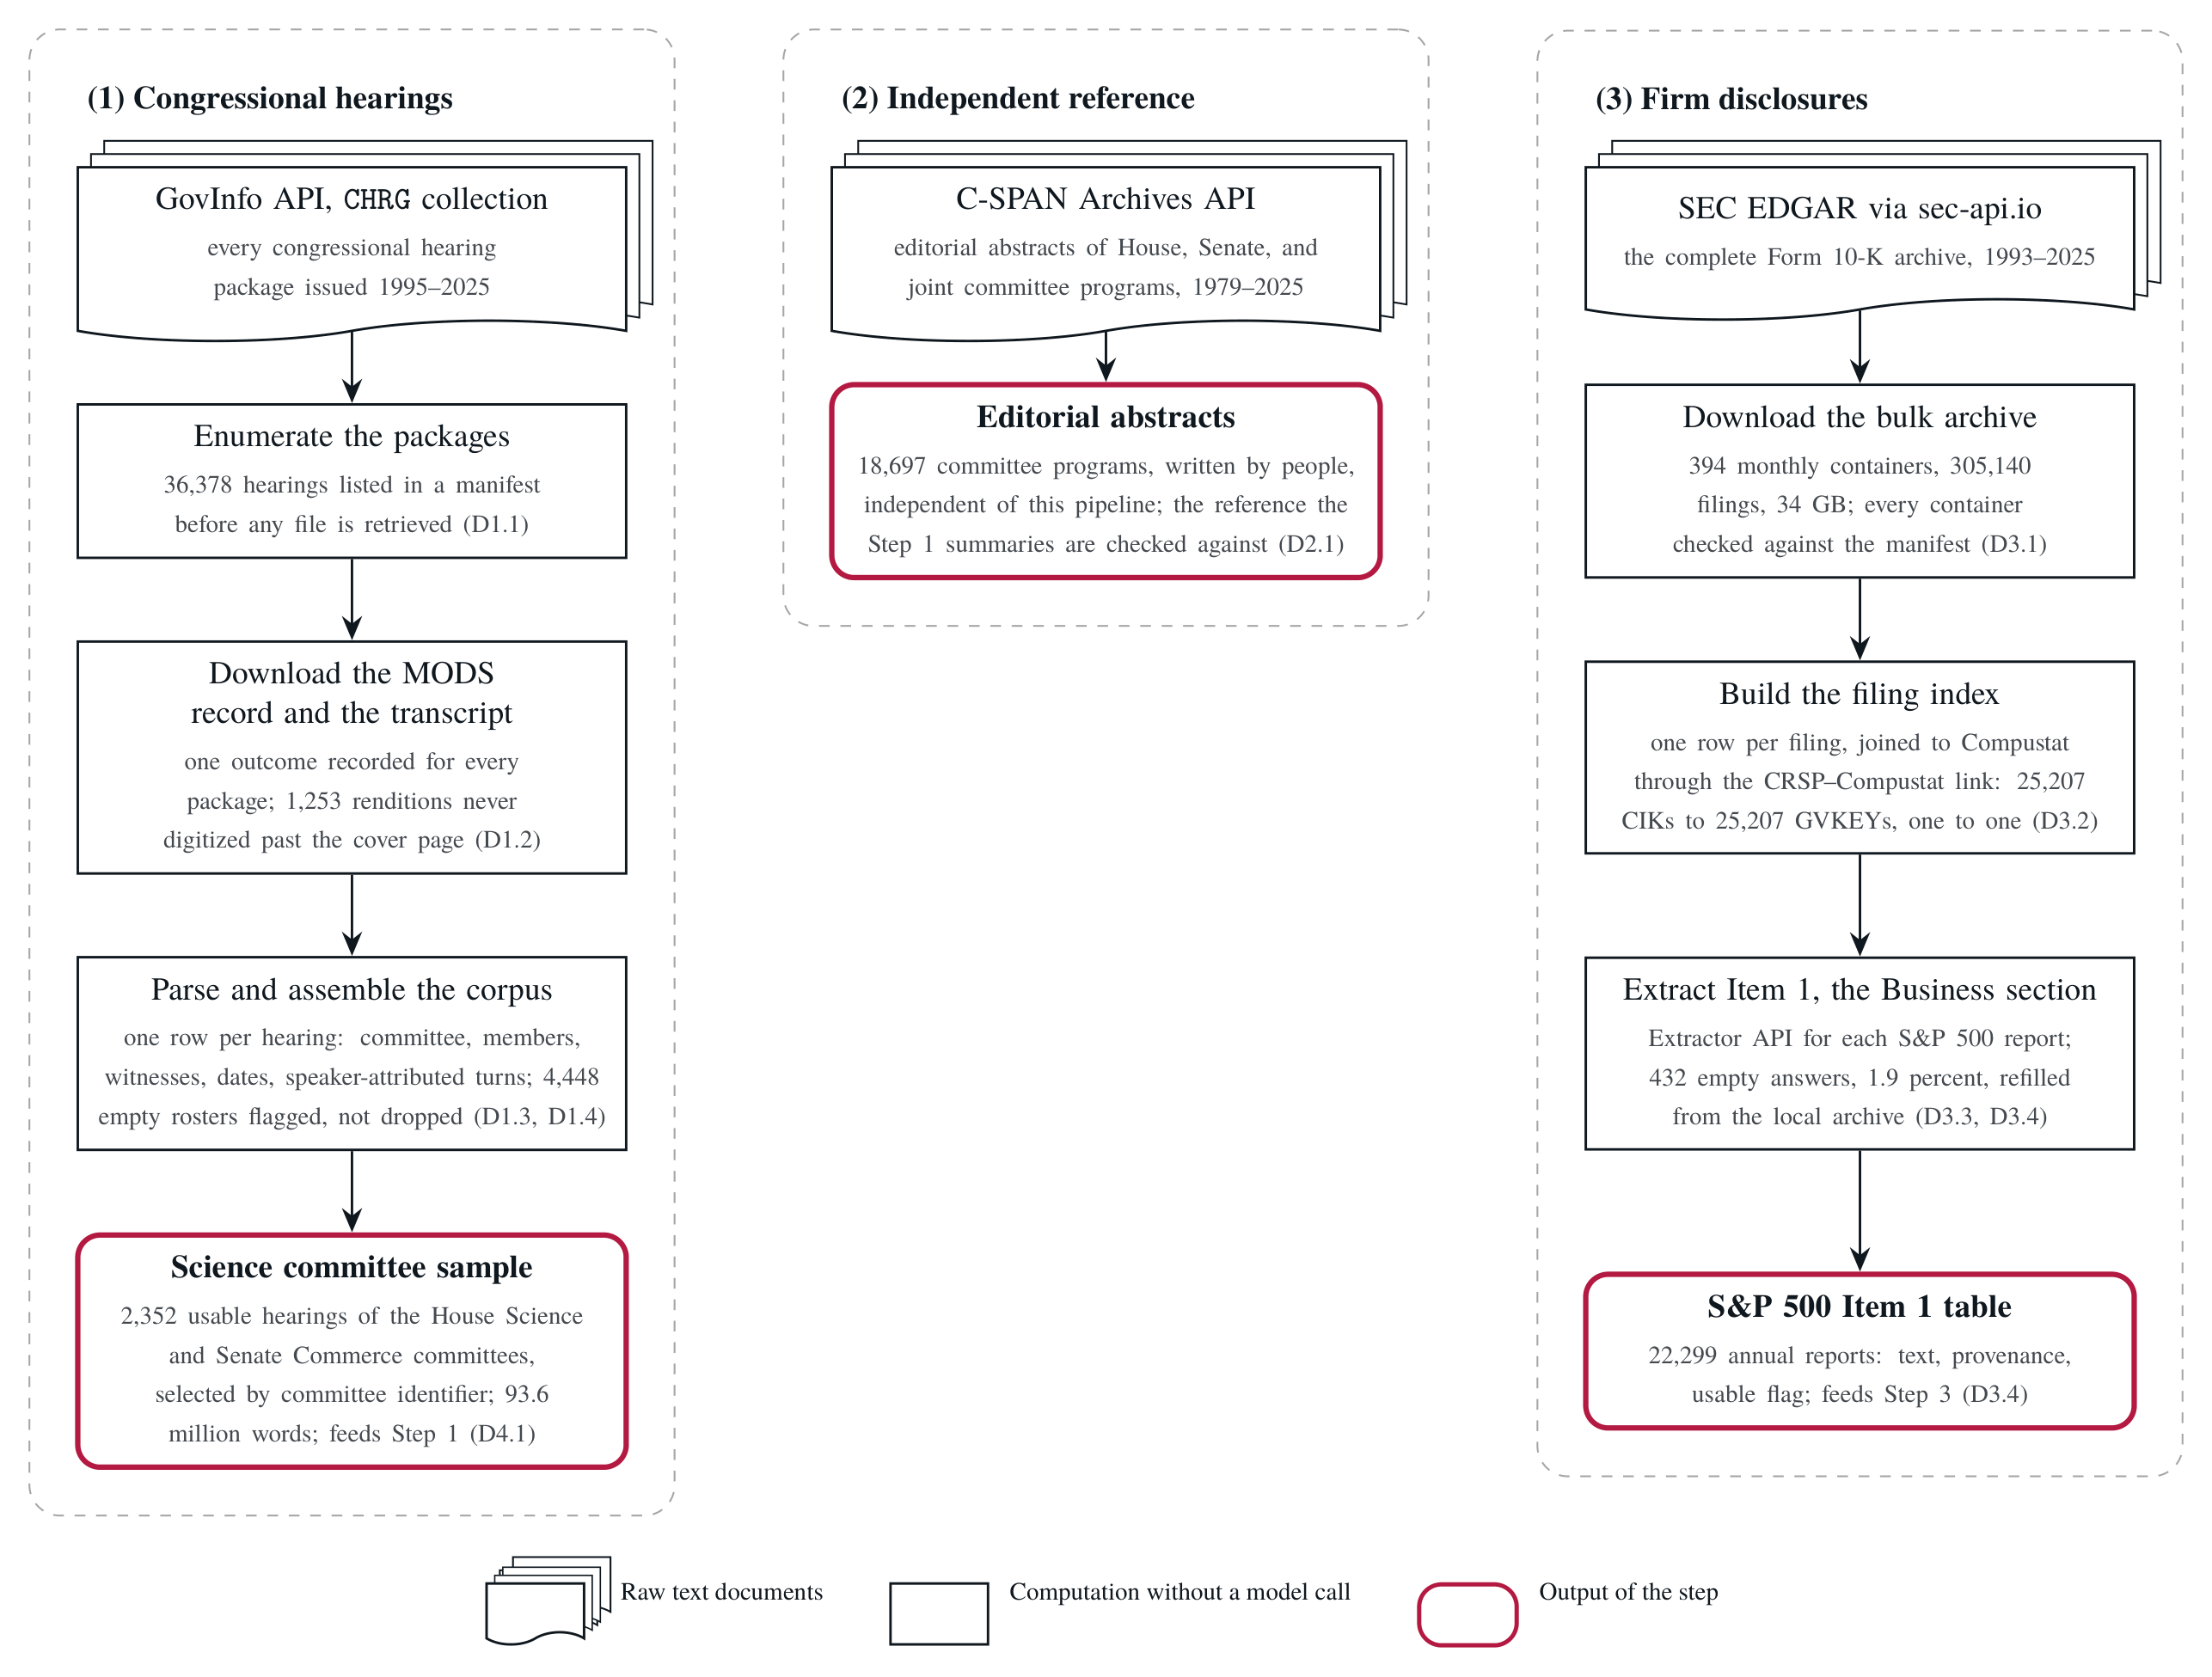

In [1]:
from pathlib import Path
from IPython.display import Image, display

PROJECT_FOLDER = Path.cwd().resolve().parents[0]  # this notebook sits one level below the clone
display(Image(filename=PROJECT_FOLDER / "R - Results/figures/D - Data Collection and Processing/fig_dataset_construction.png", width=900))

Three rails run side by side. The hearings rail lists every package GovInfo issued, downloads each one, parses it into a table with speaker-attributed turns, and draws the science committee sample. The reference rail collects C-SPAN's editorial abstract of every committee program, the independent text the summaries of Step 1 are checked against. The filings rail downloads the complete 10-K archive, joins every filing to its Compustat firm, extracts Item 1, and assembles the S&P 500 Item 1 table.

Four rules hold on every rail.

1. **Enumerate before retrieving.** [D1.1 - GovInfo - Enumerate Hearings](D1%20-%20GovInfo%20Congressional%20Hearings/D1.1%20-%20GovInfo%20-%20Enumerate%20Hearings.ipynb) lists every package in GovInfo's manifest, and [D3.1 - SEC 10-K - Download Bulk Containers](D3%20-%20SEC%20Form%2010-K%20Corporate%20Filings/D3.1%20-%20SEC%2010-K%20-%20Download%20Bulk%20Containers.ipynb) saves sec-api's dataset manifest, before any file is fetched. Every later count is a subtraction against a stated list, not a guess from what is on disk.
2. **Record an outcome for every file.** [D1.2 - GovInfo - Download Hearings](D1%20-%20GovInfo%20Congressional%20Hearings/D1.2%20-%20GovInfo%20-%20Download%20Hearings.ipynb) and [D3.3 - SEC 10-K - Extract 10-K Items](D3%20-%20SEC%20Form%2010-K%20Corporate%20Filings/D3.3%20-%20SEC%2010-K%20-%20Extract%2010-K%20Items.ipynb) write one status line per attempt. A file GovInfo never digitized, or an item a filing does not contain, is a recorded fact, not a silent gap.
3. **Parse and link.** [D1.3 - GovInfo - Parse MODS Metadata](D1%20-%20GovInfo%20Congressional%20Hearings/D1.3%20-%20GovInfo%20-%20Parse%20MODS%20Metadata.ipynb) and [D1.4 - GovInfo - Build Hearing Corpus](D1%20-%20GovInfo%20Congressional%20Hearings/D1.4%20-%20GovInfo%20-%20Build%20Hearing%20Corpus.ipynb) turn the transcripts into one row per hearing with speaker-attributed turns. [D3.2 - SEC 10-K - Build Filing Index & Linkage](D3%20-%20SEC%20Form%2010-K%20Corporate%20Filings/D3.2%20-%20SEC%2010-K%20-%20Build%20Filing%20Index%20%26%20Linkage.ipynb) joins each filing to its Compustat firm through the CRSP-Compustat link, one CIK to one GVKEY.
4. **Keep the usability decision visible.** Nothing is dropped while the corpus is built. `usable` columns carry the decision, and [D4.1 - SST - Build SST Sample](D4%20-%20SST%20Sample%20Construction/D4.1%20-%20SST%20-%20Build%20SST%20Sample.ipynb) applies it when it draws the sample.

## 2. Datasets

| Dataset | Provider | Window | Identifiers | Final output, in the subfolder's `Processed` folder |
|---|---|---|---|---|
| Congressional hearings | U.S. Government Publishing Office, GovInfo API, `CHRG` collection | Issued 1995 to 2025 | `packageId`, `congress`, committee `authorityId`, member `bioGuideId` | `hearings_all.parquet` (D1): 36,378 hearings with metadata, speaker-attributed turns, and a `usable` flag |
| Science committee sample | Built from the hearings | 1996 to 2025 | `packageId` | `hearings_sst.parquet` (D4): the 2,352 usable hearings of the House Science and Senate Commerce committees |
| C-SPAN reference abstracts | C-SPAN Archives API | Programs 1979 to 2025 | `id`, the video id | `programs.parquet` (D2): 18,697 committee programs with their editorial abstract |
| SEC Form 10-K filings | sec-api.io, bulk dataset and Extractor API | Filed 1993 to 2025 | `accessionNo`, `cik`, `gvkey`, `fyear` | `filings.parquet` (D3): 158,396 annual reports joined to Compustat; `sample_firms.parquet`: 25,207 firms; `sp500_10k_item1.parquet`: 22,299 S&P 500 reports with the cleaned Item 1 text |

## 3. The notebooks, in running order

Each notebook does one step and reads only files the notebooks above it wrote. Open any one of them to see the step in full; the links below are relative to this folder.

| Notebook | What it does | Reads | Writes |
|---|---|---|---|
| [D1.1 - GovInfo - Enumerate Hearings](D1%20-%20GovInfo%20Congressional%20Hearings/D1.1%20-%20GovInfo%20-%20Enumerate%20Hearings.ipynb) | Lists every hearing package GovInfo issued from 1995 to 2025 | GovInfo API | `Raw/manifest/packages_all.parquet`, 36,378 rows |
| [D1.2 - GovInfo - Download Hearings](D1%20-%20GovInfo%20Congressional%20Hearings/D1.2%20-%20GovInfo%20-%20Download%20Hearings.ipynb) | Fetches the MODS record and the HTML transcript of each package, one recorded outcome each | the manifest; GovInfo API | `Raw/<year>/mods`, `Raw/<year>/html`, `Raw/status` |
| [D1.3 - GovInfo - Parse MODS Metadata](D1%20-%20GovInfo%20Congressional%20Hearings/D1.3%20-%20GovInfo%20-%20Parse%20MODS%20Metadata.ipynb) | Builds one row per hearing: committees, members, witnesses, dates, transcript availability | the MODS records and the status log | `Interim/hearings.parquet` and the committee and member tables |
| [D1.4 - GovInfo - Build Hearing Corpus](D1%20-%20GovInfo%20Congressional%20Hearings/D1.4%20-%20GovInfo%20-%20Build%20Hearing%20Corpus.ipynb) | Adds the speaker-attributed turns and writes the corpus | the hearing table and the transcripts | `Processed/hearings_all.parquet` |
| [D2.1 - C-SPAN - Collect Reference Abstracts](D2%20-%20C-SPAN%20Reference%20Abstracts/D2.1%20-%20C-SPAN%20-%20Collect%20Reference%20Abstracts.ipynb) | Collects C-SPAN's abstract of every committee program | C-SPAN Archives API | `Processed/programs.parquet`, 18,697 rows |
| [D3.1 - SEC 10-K - Download Bulk Containers](D3%20-%20SEC%20Form%2010-K%20Corporate%20Filings/D3.1%20-%20SEC%2010-K%20-%20Download%20Bulk%20Containers.ipynb) | Downloads the complete 10-K archive, 394 containers, 34 GB | sec-api.io bulk dataset | `Raw/form10k_index.json`, `Raw/form10k/*.zip` |
| [D3.2 - SEC 10-K - Build Filing Index & Linkage](D3%20-%20SEC%20Form%2010-K%20Corporate%20Filings/D3.2%20-%20SEC%2010-K%20-%20Build%20Filing%20Index%20%26%20Linkage.ipynb) | Builds one row per annual report, joined to Compustat through the CRSP-Compustat link | the containers; two WRDS files in `Raw/firm_id` | `Processed/filings.parquet`, `Processed/sample_firms.parquet` |
| [D3.3 - SEC 10-K - Extract 10-K Items](D3%20-%20SEC%20Form%2010-K%20Corporate%20Filings/D3.3%20-%20SEC%2010-K%20-%20Extract%2010-K%20Items.ipynb) | Pulls named items out of each report through the Extractor API | the filing index; sec-api.io Extractor | `Interim/<run>/item<X>/...txt` and the status logs |
| [D3.4 - SEC 10-K - Assemble SP500 Item 1 Panel](D3%20-%20SEC%20Form%2010-K%20Corporate%20Filings/D3.4%20-%20SEC%2010-K%20-%20Assemble%20SP500%20Item%201%20Panel.ipynb) | Assembles one row per S&P 500 report with the cleaned Item 1 text | the extracted Item 1 files; the archive for the 432 gaps | `Processed/sp500_10k_item1.parquet`, 22,299 rows |
| [D4.1 - SST - Build SST Sample](D4%20-%20SST%20Sample%20Construction/D4.1%20-%20SST%20-%20Build%20SST%20Sample.ipynb) | Selects the usable hearings of the two science committees | `hearings_all.parquet` from D1 | `Processed/hearings_sst.parquet`, 2,352 rows |

The hearings rail (D1 then D4), the reference rail (D2), and the filings rail (D3) are independent of each other and can run in any order.

## 4. Where the data live

The notebooks read and write under one scratch root, `/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis`, in the layout [S5](../S--Style/S5--Saving_Files.md) defines: `<section>/<subfolder>/Raw`, `Interim`, and `Processed`. `Raw` holds data as received from the source. `Interim` holds what a notebook saves on the way, such as status logs and intermediate tables. `Processed` holds the final tables the later sections read. The scratch root is the one absolute path in each notebook; on another machine, change that line and put the inputs below in place.

## 5. How to obtain the inputs

**API keys.** Copy `.env.example` in this folder to `.env` and fill in three keys. `.env` is listed in `.gitignore`.

- `GOVINFO_API_KEY` for D1.1 and D1.2. Free. Register at https://api.data.gov/signup/; the key arrives by email and works at once.
- `CSPAN_API_KEY` for D2.1. Request it from api@c-spanarchives.org; it is not self-serve.
- `SEC_API_KEY` for D3.1 and D3.3. A paid sec-api.io subscription that covers the bulk 10-K dataset and the Extractor API.

**Public text.** The GovInfo packages, the C-SPAN abstracts, and the 10-K archive are all downloaded by the notebooks themselves. Running D1.1, D1.2, D2.1, and D3.1 again collects them again; the other notebooks read what is on disk.

**Licensed data from WRDS.** Two files are not in the repository and never will be. They sit in `Raw/firm_id` of the D3 scratch folder, and D3.2 reads them. Download them from WRDS with the variables and windows below.

| File | WRDS source | Variables the notebook uses | Window |
|---|---|---|---|
| `crsp_compustat_link.dta` | CRSP/Compustat Merged link history (CCM), with the Compustat company header fields | `GVKEY`, `cik`, `conm`, `tic`, `sic`, `LPERMNO`, `LINKTYPE`, `LINKPRIM`, `LINKDT`, `LINKENDDT` | Link dates 1949 to 2025-12-31; an open link has no `LINKENDDT`. 33,877 rows |
| `sp500_constituents.dta` | CRSP daily S&P 500 index constituents (Stock and Indexes, daily index membership) | `PERMNO` | Daily, 2000-01-03 to 2025-12-31; 1,107 distinct securities |

Two further files in that folder, `gvkey_cik_crosswalk.dta` and `wrds_companyid_cik_gvkey.csv`, are not read by any notebook in this section.

## 6. How to read a notebook in this section

Every notebook opens with the same table: the goal, the inputs, the outputs, and a Run row that says when it last ran and why it is not rerun. The steps follow, numbered, each with a few sentences before its code. The cell outputs are those of the August 2026 run; they are the evidence of what the step did. Three notebooks kept no outputs at the time, so each ends with a check that reads the saved files and was executed on 2026-10-31 without a download or an API call. Nothing in this section needs to run again to follow it.